# Revision experiments: every number and figure for the revised paper

The same notebook runs on **Kaggle**, **Colab** or **your own computer**; Cell 2 detects which and sets the paths. Everything is resumable: finished runs are skipped, and a run that was cut off continues from its last checkpoint (saved every 10 minutes). Each finished run is one small file in `brahmi_revision/runs/`, so runs done in different places can simply be put together in that folder.

### Kaggle (recommended)
1. Your Kaggle account must be phone-verified (needed for GPU and internet).
2. **Datasets → New Dataset**: upload `real.zip` and `synthetic.zip`, keep it private. Kaggle may unpack the ZIPs into folders; either way works.
   *Optional:* also upload the files from `MyDrive/brahmi_revision/runs/` (or `revision_results.json`) from your Colab attempts, and those runs are skipped.
3. **Create → New Notebook → File → Import Notebook**: upload this file.
4. In the right panel: **Add Input** → your dataset. **Settings**: Accelerator **GPU T4 x2**, Internet **on**.
5. **Save Version → Save & Run All (Commit)**. It runs in the background; you can close the browser. When it finishes, the results are in the version's **Output**, folder `brahmi_revision/`.
6. If a run stops early: open the notebook, **Add Input** → the Output of its previous version, and Save & Run All again. Finished runs and the checkpoint are picked up from there.

### Colab
*Runtime → Change runtime type → T4 GPU*, then *Run all*. The ZIPs are read from `MyDrive/real.zip` and `MyDrive/synthetic.zip`; results go to `MyDrive/brahmi_revision/`. After a disconnect or usage limit, *Run all* again. Without a GPU, a CPU runtime still does the Random Forest and XGBoost runs. At the end R10 disconnects the runtime so it stops using your quota.

### Your own computer (NVIDIA GPU)
1. Install PyTorch **with CUDA** using the selector on pytorch.org, then Jupyter (or use VS Code).
2. Put `real.zip` and `synthetic.zip` in a folder `data` next to this notebook. Results go to `brahmi_revision/` next to it.
3. Run all. GPUs with less than 5.5 GB of memory skip VGG-16 (it does not fit); run those two runs on Kaggle and copy their files into `brahmi_revision/runs/`. On Windows, images are loaded in the main process, which is slower but gives the same kind of results.

The setup cells are adapted from `BrahmiCharacterRecognition_finalCode.ipynb` (Cells 3–5 unchanged); the revision cells R1–R10 follow them.

**What it does**
- Splits Real (388) and Synthetic (1,500) once, reproducibly (files sorted, seed 42). The Combined set is the union of those two splits, so all three configurations share the same **59 real test photographs**.
- Trains Visformer-Small, a Basic CNN, Random Forest and XGBoost (all three configurations), and VGG-16, ResNet-34, Xception, and ViT-Small/16 frozen and fine-tuned (Combined and Real configurations). Every neural model uses the main notebook's exact recipe.

**Outputs for the paper**
- R8 prints `\setresv{...}{...}` lines. Paste them into the paper's preamble between the BEGIN/END markers.
- Figures go to `brahmi_revision/figures/`: `training_curves_real.png`, `confusion_matrices.png`, `gradcam_real.png` and `gradcam_synthetic.png`. Upload them to your LaTeX project with these exact names. R9 also puts them, with the values file, in `brahmi_revision/revision_outputs.zip`.


CELL 1: Setup & Install



In [1]:
# ============================================================
# CELL 1: Environment Setup & GPU Check
# ============================================================
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    gpu_props = torch.cuda.get_device_properties(0)
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {gpu_props.total_memory / 1e9:.1f} GB")
    print(f"Free Memory: {torch.cuda.mem_get_info(0)[0] / 1e9:.1f} GB")
else:
    print("⚠ No GPU visible to PyTorch.")
    print("  Kaggle: Settings → Accelerator → GPU T4 x2 (needs a phone-verified account)")
    print("  Colab:  Runtime → Change runtime type → T4 GPU")
    print("  Own computer: install PyTorch with CUDA from pytorch.org (see the notes at the top)")

%pip install -q timm==0.9.12 grad-cam xgboost scikit-learn matplotlib seaborn tqdm
print("✅ All packages installed!")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 15.6 GB
Free Memory: 15.5 GB
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
✅ All packages installed!


CELL 2: Platform, data and output locations

In [2]:
# ============================================================
# CELL 2: Where this runs, where the data is, where the results go.
#         Works on Kaggle, Colab and your own computer without edits.
# ============================================================
import os, shutil

LOCAL_DATA_DIR = "./data"   # own computer only: folder holding real.zip and synthetic.zip

# Kaggle is checked first: its image also has the google.colab package installed,
# but only a real Colab runtime has /var/colab/hostname (the file Drive mounting needs).
if "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.isdir("/kaggle/input"):
    PLATFORM = "kaggle"
elif os.path.exists("/var/colab/hostname") or "COLAB_RELEASE_TAG" in os.environ:
    PLATFORM = "colab"
else:
    PLATFORM = "local"


def find_data(base, name, work):
    """Return a ZIP of dataset `name` ('real' or 'synthetic') found anywhere under `base`.
    Accepts name.zip, or a folder called `name` (Kaggle may unpack uploaded ZIPs). A folder is
    zipped, so the main notebook's load_dataset() is used unchanged."""
    other = "synthetic" if name == "real" else "real"
    zips, dirs = [], []
    for root, subdirs, files in os.walk(base):
        subdirs[:] = sorted(d for d in subdirs if not d.startswith((".", "__MACOSX")) and d != "brahmi_revision")
        zips += [os.path.join(root, f) for f in files if f.lower() == f"{name}.zip"]
        dirs += [os.path.join(root, d) for d in subdirs if d.lower() == name]
    if zips:
        return min(zips, key=len)
    # a folder that also holds the other dataset is the dataset's root, not this dataset
    dirs = [d for d in dirs if not any(x.lower() in (other, other + ".zip") for x in os.listdir(d))]
    if not dirs:
        raise FileNotFoundError(f"Could not find {name}.zip, or a folder named '{name}', in {os.path.abspath(base)}")
    src = min(dirs, key=len)
    out = shutil.make_archive(os.path.join(work, f"{name}_from_folder"), "zip", root_dir=src)
    print(f"   Found folder {src}; zipped it to {out}")
    return out


if PLATFORM == "colab":
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = "/content"
    DATA = {"real": "/content/drive/MyDrive/real.zip", "synthetic": "/content/drive/MyDrive/synthetic.zip"}
    OUT_DIR = "/content/drive/MyDrive/brahmi_revision"
    IMPORT_DIRS = []                                   # Drive keeps results between sessions
    NUM_WORKERS = 2
elif PLATFORM == "kaggle":
    WORK_DIR = "/kaggle/temp" if os.path.isdir("/kaggle/temp") else "/tmp"   # not saved as output
    DATA = {k: find_data("/kaggle/input", k, WORK_DIR) for k in ("real", "synthetic")}
    OUT_DIR = "/kaggle/working/brahmi_revision"        # becomes the notebook's Output
    IMPORT_DIRS = ["/kaggle/input"]                    # earlier results added as inputs are picked up in R6
    NUM_WORKERS = min(4, os.cpu_count() or 2)
else:
    WORK_DIR = os.path.abspath(".")
    DATA = {k: find_data(LOCAL_DATA_DIR, k, WORK_DIR) for k in ("real", "synthetic")}
    OUT_DIR = os.path.abspath("./brahmi_revision")
    IMPORT_DIRS = []
    # Windows starts DataLoader workers as new processes, which cannot see classes defined in a
    # notebook, so there the images are loaded in the main process (slower, same results).
    NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 2)

DATASET_CONFIGS = {
    key: {"zip_path": DATA[key], "extract_dir": os.path.join(WORK_DIR, f"brahmi_{key}"), "description": desc}
    for key, desc in (("real", "Real Inscriptions"), ("synthetic", "Synthetic Inscriptions"))
}
os.makedirs(OUT_DIR, exist_ok=True)

print(f"✅ Running on: {PLATFORM}")
for cfg in DATASET_CONFIGS.values():
    print(f"   {cfg['description']:24s}: {cfg['zip_path']}")
print(f"   {'Results go to':24s}: {OUT_DIR}")
print(f"   {'DataLoader workers':24s}: {NUM_WORKERS}")

   Found folder /kaggle/input/datasets/wickns/real-zip/real; zipped it to /tmp/real_from_folder.zip
   Found folder /kaggle/input/datasets/wickns/synthetic-zip/synthetic; zipped it to /tmp/synthetic_from_folder.zip
✅ Running on: kaggle
   Real Inscriptions       : /tmp/real_from_folder.zip
   Synthetic Inscriptions  : /tmp/synthetic_from_folder.zip
   Results go to           : /kaggle/working/brahmi_revision
   DataLoader workers      : 4


CELL 3: All Imports & Global Settings

In [3]:
# ============================================================
# CELL 3: All Imports, Seed, Device, Global Config
# ============================================================
import os, random, copy, time, gc, warnings, zipfile, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import autocast, GradScaler
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from collections import Counter
import timm
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
warnings.filterwarnings('ignore')

# ── Global training hyperparameters ─────────────────────────
IMG_SIZE      = 224
BATCH_SIZE    = 16
NUM_EPOCHS    = 60
WARMUP_EPOCHS = 5

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Imports complete | Device: {device}")

✅ Imports complete | Device: cuda


CELL 4: All Helper Classes & Functions

In [4]:
# ============================================================
# CELL 4: All Helper Classes & Functions
# (Dataset, Transforms, Loss, EMA, Scheduler, etc.)
# ============================================================

# ── Dataset class ────────────────────────────────────────────
class BrahmiDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels      = labels
        self.transform   = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        try:
            image = Image.open(self.image_paths[idx]).convert('RGB')
        except Exception as e:
            image = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (128, 128, 128))
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(self.labels[idx], dtype=torch.long)


# ── Transforms ───────────────────────────────────────────────
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE + 16, IMG_SIZE + 16)),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomRotation(degrees=8),
    transforms.RandomPerspective(distortion_scale=0.15, p=0.3),
    transforms.RandomAffine(
        degrees=0, translate=(0.05, 0.05),
        scale=(0.92, 1.08), shear=3,
    ),
    transforms.ColorJitter(
        brightness=0.4, contrast=0.4,
        saturation=0.2, hue=0.05,
    ),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.8)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.15)),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


# ── Weighted Focal Loss ──────────────────────────────────────
class WeightedFocalLoss(nn.Module):
    def __init__(self, class_weights, gamma=2.0, smoothing=0.1):
        super().__init__()
        self.class_weights = class_weights
        self.gamma         = gamma
        self.smoothing     = smoothing

    def forward(self, inputs, targets):
        ce    = F.cross_entropy(
            inputs, targets,
            weight=self.class_weights,
            reduction='none',
            label_smoothing=self.smoothing,
        )
        pt    = torch.exp(-ce)
        focal = (1 - pt) ** self.gamma * ce
        return focal.mean()


# ── EMA ──────────────────────────────────────────────────────
class ModelEMA:
    def __init__(self, model, decay=0.9999):
        self.module = copy.deepcopy(model)
        self.module.eval()
        self.decay  = decay
        for p in self.module.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for ep, mp in zip(self.module.parameters(), model.parameters()):
            ep.mul_(self.decay).add_(mp.detach(), alpha=1 - self.decay)
        for eb, mb in zip(self.module.buffers(), model.buffers()):
            eb.copy_(mb)


# ── Early Stopping ───────────────────────────────────────────
class EarlyStopping:
    def __init__(self, patience=15, min_delta=0.001):
        self.patience   = patience
        self.min_delta  = min_delta
        self.counter    = 0
        self.best_score = None

    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        if score < self.best_score - self.min_delta:
            self.best_score = score
            self.counter    = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                return True
        return False


# ── Warmup + Cosine LR ───────────────────────────────────────
class WarmupCosineScheduler:
    def __init__(self, optimizer, warmup_epochs, total_epochs,
                 min_lr_ratio=0.01):
        self.optimizer = optimizer
        self.warmup    = warmup_epochs
        self.total     = total_epochs
        self.min_ratio = min_lr_ratio
        self.base_lrs  = [g['lr'] for g in optimizer.param_groups]

    def step(self, epoch):
        if epoch < self.warmup:
            factor = (epoch + 1) / self.warmup
        else:
            progress = (epoch - self.warmup) / (self.total - self.warmup)
            factor   = self.min_ratio + 0.5 * (1 - self.min_ratio) * (
                1 + np.cos(np.pi * progress))
        for g, base in zip(self.optimizer.param_groups, self.base_lrs):
            g['lr'] = base * factor
        return self.optimizer.param_groups[0]['lr']


# ── MixUp / CutMix ───────────────────────────────────────────
def mixup_data(x, y, alpha=0.2):
    lam   = np.random.beta(alpha, alpha)
    idx   = torch.randperm(x.size(0)).to(x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

def cutmix_data(x, y, alpha=1.0):
    lam  = np.random.beta(alpha, alpha)
    idx  = torch.randperm(x.size(0)).to(x.device)
    _, _, H, W = x.shape
    cut_w = int(W * np.sqrt(1 - lam))
    cut_h = int(H * np.sqrt(1 - lam))
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H)
    x2 = np.clip(cx + cut_w // 2, 0, W)
    y2 = np.clip(cy + cut_h // 2, 0, H)
    mixed       = x.clone()
    mixed[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - ((x2 - x1) * (y2 - y1) / (W * H))
    return mixed, y, y[idx], lam

def mixed_criterion(criterion, pred, ya, yb, lam):
    return lam * criterion(pred, ya) + (1 - lam) * criterion(pred, yb)


# ── Validation ───────────────────────────────────────────────
@torch.no_grad()
def validate_amp(model, loader, criterion, device, epoch, phase='Val'):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    pbar = tqdm(loader, desc=f'Epoch {epoch+1} [{phase}]', leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with autocast('cuda'):
            outputs = model(images)
            loss    = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        _, predicted  = outputs.max(1)
        total        += labels.size(0)
        correct      += predicted.eq(labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        pbar.set_postfix({'loss': f'{loss.item():.4f}',
                          'acc':  f'{100.*correct/total:.2f}%'})
    return running_loss / total, 100. * correct / total, all_preds, all_labels


# ── TTA Evaluation ───────────────────────────────────────────
@torch.no_grad()
def evaluate_with_tta(model, loader, device):
    model.eval()
    correct, total = 0, 0
    tta_preds, tta_labels = [], []
    pbar = tqdm(loader, desc='TTA Evaluation', leave=True)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        preds  = []
        with autocast('cuda'):
            preds.append(F.softmax(model(images), dim=1))
        for angle in [-5, 5, -3, 3]:
            with autocast('cuda'):
                preds.append(F.softmax(
                    model(transforms.functional.rotate(images, angle)), dim=1))
        for shift in [(2, 0), (-2, 0), (0, 2)]:
            with autocast('cuda'):
                preds.append(F.softmax(
                    model(transforms.functional.affine(
                        images, angle=0, translate=shift,
                        scale=1.0, shear=0)), dim=1))
        avg = torch.stack(preds).mean(0)
        _, predicted = avg.max(1)
        total   += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        tta_preds.extend(predicted.cpu().numpy())
        tta_labels.extend(labels.cpu().numpy())
        pbar.set_postfix({'acc': f'{100.*correct/total:.2f}%'})
    return 100. * correct / total, tta_preds, tta_labels


# ── GradCAM helper ───────────────────────────────────────────
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img  = (tensor.cpu() * std + mean).clamp(0, 1)
    return img.permute(1, 2, 0).numpy()

print("✅ All helper classes & functions defined")

✅ All helper classes & functions defined


CELL 5: Core Pipeline Functions

In [5]:
import os, random, copy, time, gc, warnings, zipfile, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import autocast, GradScaler
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from collections import Counter
import timm
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
warnings.filterwarnings('ignore')


# ============================================================
# CELL 5: Core Pipeline Functions
# (load_dataset, build_loaders, build_model, train, evaluate,
#  generate_gradcam, save_all_results)
# These are called by the master loop in Cell 6
# ============================================================

def load_dataset(cfg):
    """Extract ZIP and collect image paths + labels."""
    zip_path    = cfg["zip_path"]
    extract_dir = cfg["extract_dir"]

    # Fresh extract every time to avoid stale data
    if os.path.exists(extract_dir):
        shutil.rmtree(extract_dir)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_dir)

    image_paths, image_labels = [], []
    valid_ext = ('.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.webp')
    for root, _, files in os.walk(extract_dir):
        for f in files:
            if f.lower().endswith(valid_ext):
                image_paths.append(os.path.join(root, f))
                image_labels.append(os.path.basename(root))

    classes     = sorted(set(image_labels))
    num_classes = len(classes)
    counts      = Counter(image_labels)

    print(f"   Images : {len(image_paths)}")
    print(f"   Classes: {num_classes}  "
          f"(min={min(counts.values())} max={max(counts.values())})")
    return image_paths, image_labels, num_classes


def build_loaders(image_paths, image_labels, num_classes):
    """Encode labels, split, create DataLoaders."""
    label_encoder  = LabelEncoder()
    encoded_labels = label_encoder.fit_transform(image_labels)

    X_train, X_temp, y_train, y_temp = train_test_split(
        image_paths, encoded_labels,
        test_size=0.30, stratify=encoded_labels, random_state=42
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.50, stratify=y_temp, random_state=42
    )

    # Weighted sampler for imbalanced classes
    train_counts   = Counter(y_train)
    total_train    = len(y_train)
    weight_dict    = {c: total_train / v for c, v in train_counts.items()}
    sample_weights = torch.tensor(
        [weight_dict[l] for l in y_train], dtype=torch.float)
    sampler = WeightedRandomSampler(sample_weights, len(sample_weights), True)

    train_loader = DataLoader(
        BrahmiDataset(X_train, y_train, train_transform),
        batch_size=BATCH_SIZE, sampler=sampler,
        num_workers=2, pin_memory=True, drop_last=True,
    )
    val_loader = DataLoader(
        BrahmiDataset(X_val, y_val, val_transform),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=2, pin_memory=True,
    )
    test_loader = DataLoader(
        BrahmiDataset(X_test, y_test, val_transform),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=2, pin_memory=True,
    )

    print(f"   Split  → Train:{len(X_train)} Val:{len(X_val)} Test:{len(X_test)}")
    return (train_loader, val_loader, test_loader,
            label_encoder, X_test, y_test, train_counts, total_train)


def build_model_and_optim(num_classes, train_counts, total_train):
    """Build fresh Visformer + loss + optimiser + scheduler."""
    gc.collect()
    torch.cuda.empty_cache()

    model = timm.create_model(
        'visformer_small', pretrained=True,
        num_classes=num_classes,
        drop_rate=0.15, drop_path_rate=0.15,
    ).to(device)

    # Class weights for focal loss
    cw = torch.zeros(num_classes)
    for c in range(num_classes):
        cw[c] = total_train / (num_classes * train_counts.get(c, 1))
    cw = (cw / cw.sum() * num_classes).to(device)
    criterion = WeightedFocalLoss(cw, gamma=2.0, smoothing=0.1)

    # Discriminative LR groups
    head, late, early = [], [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if 'head' in name or 'classifier' in name:
            head.append(param)
        elif 'stage3' in name or 'norm' in name:
            late.append(param)
        else:
            early.append(param)

    optimizer = optim.AdamW([
        {'params': early, 'lr': 5e-6,  'name': 'backbone_early'},
        {'params': late,  'lr': 5e-5,  'name': 'backbone_late'},
        {'params': head,  'lr': 5e-4,  'name': 'head'},
    ], weight_decay=0.05, betas=(0.9, 0.999))

    scheduler = WarmupCosineScheduler(optimizer, WARMUP_EPOCHS, NUM_EPOCHS)
    return model, criterion, optimizer, scheduler


def train_one_dataset(cfg, dataset_key, model, criterion,
                       optimizer, scheduler,
                       train_loader, val_loader):
    """
    Full training loop for one dataset.
    Returns history dict and best_val_acc.
    """
    scaler         = GradScaler('cuda')
    ema_model      = ModelEMA(model, decay=0.9999)
    early_stopping = EarlyStopping(patience=15)

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss':   [], 'val_acc':   [],
        'val_loss_ema': [], 'val_acc_ema': [], 'lr': [],
    }
    best_val_acc = 0.0
    best_epoch   = 0

    print(f"\n{'='*70}")
    print(f"🚀 TRAINING: {cfg['description']}")
    print(f"{'='*70}")
    start_time = time.time()

    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()
        current_lr  = scheduler.step(epoch)
        history['lr'].append(current_lr)

        # ── Train epoch ────────────────────────────────────
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        pbar = tqdm(train_loader,
                    desc=f'[{cfg["description"]}] '
                         f'Epoch {epoch+1}/{NUM_EPOCHS}',
                    leave=False)
        for images, labels in pbar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            rand = np.random.random()
            with autocast('cuda'):
                if rand < 0.3:
                    mx, ya, yb, lam = mixup_data(images, labels, 0.2)
                    out  = model(mx)
                    loss = mixed_criterion(criterion, out, ya, yb, lam)
                elif rand < 0.5:
                    mx, ya, yb, lam = cutmix_data(images, labels, 1.0)
                    out  = model(mx)
                    loss = mixed_criterion(criterion, out, ya, yb, lam)
                else:
                    out  = model(images)
                    loss = criterion(out, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            ema_model.update(model)

            running_loss += loss.item() * images.size(0)
            _, pred        = out.max(1)
            total         += labels.size(0)
            correct       += pred.eq(labels).sum().item()

        train_loss = running_loss / total
        train_acc  = 100. * correct / total
        torch.cuda.empty_cache()

        # ── Validate ───────────────────────────────────────
        val_loss,     val_acc,     _, _ = validate_amp(
            model,            val_loader, criterion, device, epoch, 'Val')
        ema_val_loss, ema_val_acc, _, _ = validate_amp(
            ema_model.module, val_loader, criterion, device, epoch, 'EMA')
        torch.cuda.empty_cache()

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_loss_ema'].append(ema_val_loss)
        history['val_acc_ema'].append(ema_val_acc)

        best_current = max(val_acc, ema_val_acc)
        use_ema      = ema_val_acc > val_acc

        ep_time = time.time() - epoch_start
        print(f"  [{epoch+1:3d}/{NUM_EPOCHS}] "
              f"Train:{train_acc:5.2f}% "
              f"Val:{val_acc:5.2f}% "
              f"EMA:{ema_val_acc:5.2f}% "
              f"LR:{current_lr:.1e} "
              f"{ep_time:.0f}s")

        if best_current > best_val_acc:
            best_val_acc = best_current
            best_epoch   = epoch + 1
            # Save best weights + full checkpoint
            save_state = (ema_model.module if use_ema else model).state_dict()

            # Save to a temporary local path first, then copy to Drive
            temp_local_save_path = f"/content/temp_weights_{dataset_key}.pth"
            torch.save({
                'epoch':                  epoch,
                'model_state_dict':       save_state,
                'optimizer_state_dict':   optimizer.state_dict(),
                'val_acc':                float(best_current),
                'num_classes':            int(model.num_classes),
                'label_encoder_classes':  [],   # filled after return
                'used_ema':               bool(use_ema),
                'history':                history,
                'dataset_key':            dataset_key,
                'description':            cfg['description'],
            }, temp_local_save_path)

            # Copy the saved file to Google Drive
            shutil.copy(temp_local_save_path, cfg['weight_path'])

            marker = "EMA" if use_ema else "Reg"
            print(f"  ★ NEW BEST {best_current:.2f}% ({marker}) "
                  f"→ {cfg['weight_path']}")

        torch.cuda.reset_peak_memory_stats()
        if early_stopping(min(val_loss, ema_val_loss)):
            print(f"  ⚠ Early stopping at epoch {epoch+1}")
            break

    total_time = time.time() - start_time
    print(f"\n✅ {cfg['description']} done — "
          f"{total_time/60:.1f} min | Best: {best_val_acc:.2f}% "
          f"(epoch {best_epoch})")
    return history, best_val_acc, best_epoch


def evaluate_dataset(model, test_loader, criterion,
                      label_encoder, result_dir, cfg):
    """
    Run standard + TTA evaluation, save confusion matrix,
    per-class accuracy, and classification report.
    Returns (test_acc, tta_acc, report, cm, final_preds, final_labels)
    """
    os.makedirs(result_dir, exist_ok=True)
    class_names = label_encoder.classes_

    # Standard
    test_loss, test_acc, test_preds, test_labels = validate_amp(
        model, test_loader, criterion, device, 0, 'Test')

    # TTA
    tta_acc, tta_preds, tta_labels = evaluate_with_tta(
        model, test_loader, device)

    final_preds  = tta_preds
    final_labels = tta_labels

    print(f"\n  Standard : {test_acc:.2f}%")
    print(f"  TTA      : {tta_acc:.2f}%  (+{tta_acc - test_acc:.2f}%)")

    # Classification report
    report = classification_report(
        final_labels, final_preds,
        target_names=class_names,
        output_dict=True, zero_division=0,
    )
    with open(f"{result_dir}/classification_report.txt", 'w') as f:
        f.write(f"Dataset: {cfg['description']}\n")
        f.write(f"Standard Accuracy: {test_acc:.2f}%\n")
        f.write(f"TTA Accuracy:      {tta_acc:.2f}%\n\n")
        f.write(classification_report(
            final_labels, final_preds,
            target_names=class_names, zero_division=0))

    # Confusion matrix
    cm = confusion_matrix(final_labels, final_preds)
    fig, ax = plt.subplots(figsize=(25, 25))
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names, ax=ax)
    ax.set(xlabel='Predicted', ylabel='True',
           title=f'{cfg["description"]} — TTA Acc: {tta_acc:.2f}%')
    plt.xticks(rotation=90, fontsize=5)
    plt.yticks(rotation=0,  fontsize=5)
    plt.tight_layout()
    plt.savefig(f"{result_dir}/confusion_matrix.png",
                dpi=150, bbox_inches='tight')
    plt.close()

    # Per-class accuracy bar
    per_acc    = cm.diagonal() / cm.sum(axis=1).clip(min=1) * 100
    sorted_idx = np.argsort(per_acc)[::-1]
    colors_bar = ['green' if a > 90 else 'orange' if a > 70 else 'red'
                  for a in per_acc[sorted_idx]]
    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bar(range(len(per_acc)), per_acc[sorted_idx],
           color=colors_bar, alpha=0.7)
    ax.axhline(tta_acc, color='blue', ls='--', lw=2,
               label=f'Overall TTA: {tta_acc:.1f}%')
    ax.set(xlabel='Class (sorted)', ylabel='Accuracy (%)',
           title=f'Per-Class Accuracy — {cfg["description"]}')
    ax.legend(); ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(f"{result_dir}/per_class_accuracy.png",
                dpi=150, bbox_inches='tight')
    plt.close()

    print(f"  ✅ Reports saved → {result_dir}/")
    return test_acc, tta_acc, report, cm, final_preds, final_labels


def plot_training_curves(history, cfg, result_dir):
    """Save training curve plots for one dataset."""
    os.makedirs(result_dir, exist_ok=True)
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f'Training Curves — {cfg["description"]}', fontsize=14)

    axes[0].plot(history['train_loss'],   label='Train', color='blue')
    axes[0].plot(history['val_loss'],     label='Val',   color='red')
    axes[0].plot(history['val_loss_ema'], label='EMA',   color='green', ls='--')
    axes[0].set(xlabel='Epoch', ylabel='Loss', title='Loss')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    best_acc = max(max(history['val_acc']), max(history['val_acc_ema']))
    axes[1].plot(history['train_acc'],   label='Train', color='blue')
    axes[1].plot(history['val_acc'],     label='Val',   color='red')
    axes[1].plot(history['val_acc_ema'], label='EMA',   color='green', ls='--')
    axes[1].axhline(best_acc, color='purple', ls=':',
                    label=f'Best:{best_acc:.2f}%')
    axes[1].set(xlabel='Epoch', ylabel='Accuracy (%)', title='Accuracy')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    axes[2].plot(history['lr'], color='purple')
    axes[2].set(xlabel='Epoch', ylabel='LR',
                title='Learning Rate', yscale='log')
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{result_dir}/training_curves.png",
                dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


def generate_gradcam_for_dataset(model, label_encoder,
                                  X_test, y_test,
                                  cfg, result_dir, n_samples=20):
    """
    Generate GradCAM for n_samples random test images.
    Saves individual images + a grid summary.
    """
    os.makedirs(f"{result_dir}/gradcam", exist_ok=True)
    model.eval()

    # Target last block of stage3 in Visformer
    target_layers = [model.stage3[-1]]
    class_names   = label_encoder.classes_

    # Random sample indices
    indices = random.sample(range(len(X_test)), min(n_samples, len(X_test)))

    n_cols = 4   # original | GradCAM | original | GradCAM ...
    n_rows = (len(indices) + 1) // 2  # 2 samples per row
    fig, axes = plt.subplots(n_rows, 4,
                              figsize=(20, 5 * n_rows),
                              squeeze=False)
    fig.suptitle(f'GradCAM — {cfg["description"]}',
                 fontsize=14, fontweight='bold')

    correct_count = 0
    for plot_idx, sample_idx in enumerate(indices):
        row = plot_idx // 2
        col = (plot_idx % 2) * 2   # 0 or 2

        img_path   = X_test[sample_idx]
        true_label = class_names[y_test[sample_idx]]

        # Load & preprocess
        pil_img      = Image.open(img_path).convert('RGB').resize((224, 224))
        input_tensor = val_transform(pil_img).unsqueeze(0).to(device)

        # TTA prediction for the label
        with torch.no_grad():
            all_p = []
            with autocast('cuda'):
                all_p.append(F.softmax(model(input_tensor), dim=1))
            for angle in [-5, -3, 3, 5]:
                rot = transforms.functional.rotate(input_tensor, angle)
                with autocast('cuda'):
                    all_p.append(F.softmax(model(rot), dim=1))
            probs = torch.stack(all_p).mean(0)
        top_prob, top_idx_val = probs.max(1)
        pred_label  = class_names[top_idx_val.item()]
        confidence  = top_prob.item() * 100
        is_correct  = pred_label == true_label
        if is_correct:
            correct_count += 1

        # GradCAM
        with GradCAM(model=model,
                     target_layers=target_layers) as cam:
            targets   = [ClassifierOutputTarget(top_idx_val.item())]
            grayscale = cam(input_tensor=input_tensor,
                            targets=targets)
        rgb_img   = denormalize(input_tensor[0])
        cam_image = show_cam_on_image(rgb_img, grayscale[0], use_rgb=True)

        # ── Plot into grid ────────────────────────────────
        border_color = 'green' if is_correct else 'red'

        axes[row][col].imshow(pil_img)
        axes[row][col].set_title(
            f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
            fontsize=7,
            color=border_color,
        )
        axes[row][col].axis('off')
        # Draw border
        for spine in axes[row][col].spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(3)

        axes[row][col + 1].imshow(cam_image)
        axes[row][col + 1].set_title("GradCAM", fontsize=7)
        axes[row][col + 1].axis('off')

        # ── Save individual file ──────────────────────────
        fig_ind, ax_ind = plt.subplots(1, 2, figsize=(10, 5))
        ax_ind[0].imshow(pil_img)
        ax_ind[0].set_title(
            f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
            color=border_color)
        ax_ind[0].axis('off')
        ax_ind[1].imshow(cam_image)
        ax_ind[1].set_title('GradCAM Activation')
        ax_ind[1].axis('off')
        plt.tight_layout()
        safe_name = os.path.basename(img_path).replace(' ', '_')
        plt.savefig(
            f"{result_dir}/gradcam/{plot_idx+1:02d}_{true_label}_{safe_name}.png",
            dpi=120, bbox_inches='tight')
        plt.close(fig_ind)

    # Hide empty subplot cells
    for plot_idx in range(len(indices), n_rows * 2):
        row = plot_idx // 2
        col = (plot_idx % 2) * 2
        axes[row][col].axis('off')
        axes[row][col + 1].axis('off')

    acc_pct = 100 * correct_count / len(indices)
    fig.suptitle(
        f'GradCAM — {cfg["description"]} | '
        f'{correct_count}/{len(indices)} correct ({acc_pct:.0f}%)',
        fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{result_dir}/gradcam_grid.png",
                dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"  ✅ GradCAM grid saved → {result_dir}/gradcam_grid.png")
    print(f"  ✅ {len(indices)} individual GradCAM images → "
          f"{result_dir}/gradcam/")
    return correct_count, len(indices)

print("✅ All pipeline functions defined")


✅ All pipeline functions defined


In [6]:
# ============================================================
# R1: Prerequisites and configuration
# ============================================================
import os, gc, json, time, random, shutil, subprocess, sys, tempfile, traceback, zipfile
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torch.amp import autocast, GradScaler
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import binomtest
from tqdm import tqdm
import timm
import matplotlib.pyplot as plt
try:
    import xgboost as xgb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    import xgboost as xgb

_needed = ["DATASET_CONFIGS", "load_dataset", "BrahmiDataset", "train_transform", "val_transform",
           "build_model_and_optim", "WeightedFocalLoss", "ModelEMA", "EarlyStopping",
           "WarmupCosineScheduler", "mixup_data", "cutmix_data", "mixed_criterion",
           "validate_amp", "evaluate_with_tta", "generate_gradcam_for_dataset",
           "set_seed", "device", "NUM_EPOCHS", "WARMUP_EPOCHS", "BATCH_SIZE",
           "PLATFORM", "OUT_DIR", "NUM_WORKERS", "IMPORT_DIRS"]
_missing = [n for n in _needed if n not in globals()]
assert not _missing, f"Run Cells 1-5 first. Missing: {_missing}"
HAS_GPU = torch.cuda.is_available()

FIG_DIR = f"{OUT_DIR}/figures"
RUN_DIR = f"{OUT_DIR}/runs"                 # one result file per finished run
CKPT_DIR = f"{OUT_DIR}/checkpoints"         # training checkpoint of a run that has not finished yet
for d in (FIG_DIR, RUN_DIR, CKPT_DIR, f"{OUT_DIR}/weights"):
    os.makedirs(d, exist_ok=True)
RESULTS_JSON = f"{OUT_DIR}/revision_results.json"   # single-file format of the previous version, migrated in R6

CKPT_EVERY_MIN = 10   # minutes between training checkpoints: a disconnect loses at most about this much training
AUTO_RELEASE = True   # Colab only: R10 disconnects the runtime at the end, so an idle session stops using your quota

SOTA_MODELS = {
    "VGG16":          {"timm_name": "vgg16",                 "freeze": False, "label": "VGG-16"},
    "ResNet34":       {"timm_name": "resnet34",              "freeze": False, "label": "ResNet-34"},
    "Xception":       {"timm_name": "legacy_xception",       "freeze": False, "label": "Xception"},
    "ViT_S16_frozen": {"timm_name": "vit_small_patch16_224", "freeze": True,  "label": "ViT-Small/16 (frozen)"},
    "ViT_S16_ft":     {"timm_name": "vit_small_patch16_224", "freeze": False, "label": "ViT-Small/16 (fine-tuned)"},
}
CONFIGS = ["real", "synthetic", "real_synthetic"]
CLASSICAL = ("RF", "XGB")

# GPU runs first, most important first. Random Forest and XGBoost need no GPU, so they come last:
# if the GPU quota runs out before them, they can be done in a CPU-only session instead.
PLAN  = [(c, "Visformer_S") for c in CONFIGS]
PLAN += [(c, "BasicCNN") for c in CONFIGS]
PLAN += [("real_synthetic", m) for m in SOTA_MODELS] + [("real", m) for m in SOTA_MODELS]
PLAN += [(c, m) for m in CLASSICAL for c in CONFIGS]

SKIP_RUNS = set()     # runs this machine leaves for another one, e.g. {"real/VGG16"}
if HAS_GPU and torch.cuda.get_device_properties(0).total_memory < 5.5e9:
    SKIP_RUNS |= {f"{c}/VGG16" for c in CONFIGS}
    print("This GPU has under 5.5 GB of memory, not enough to train VGG-16 with this recipe.\n"
          "Its runs are left for Kaggle or Colab: copy their files from runs/ into this runs/ folder afterwards.")

print(f"PyTorch {torch.__version__} | timm {timm.__version__} | "
      f"GPU {torch.cuda.get_device_name(0) if HAS_GPU else 'none'}")
if not HAS_GPU:
    print("CPU-only session: R6 will do the Random Forest and XGBoost runs "
          "and leave the neural runs for a GPU session.")
print(f"{len(PLAN)} runs planned -> {RUN_DIR}/")

PyTorch 2.11.0+cu130 | timm 0.9.12 | GPU Tesla T4
22 runs planned -> /kaggle/working/brahmi_revision/runs/


In [7]:
# ============================================================
# R2: Reproducible splits. Combined = union of the Real and Synthetic splits,
#     so every configuration is tested on the same 59 real photographs.
# ============================================================
def load_sorted(key):
    cfg = DATASET_CONFIGS[key]
    paths, labels, _ = load_dataset(cfg)               # main-notebook function (extracts the ZIP)
    rel = [os.path.relpath(p, cfg["extract_dir"]).replace(os.sep, "/") for p in paths]   # same order on Windows
    order = sorted(range(len(paths)), key=lambda i: rel[i])
    return [paths[i] for i in order], [labels[i] for i in order]


def stratified_split(paths, labels):
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=42)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)
    return {"train": (list(X_tr), list(y_tr)), "val": (list(X_va), list(y_va)), "test": (list(X_te), list(y_te))}


real_paths, real_labels = load_sorted("real")
syn_paths, syn_labels = load_sorted("synthetic")
CLASSES = sorted(set(real_labels))
assert CLASSES == sorted(set(syn_labels)), f"Class folders differ: {CLASSES} vs {sorted(set(syn_labels))}"
LE = LabelEncoder().fit(CLASSES)
NUM_CLASSES = len(CLASSES)

SPLITS = {"real": stratified_split(real_paths, real_labels),
          "synthetic": stratified_split(syn_paths, syn_labels)}
SPLITS["real_synthetic"] = {s: (SPLITS["real"][s][0] + SPLITS["synthetic"][s][0],
                                SPLITS["real"][s][1] + SPLITS["synthetic"][s][1])
                            for s in ("train", "val", "test")}
DOMAIN = {p: "real" for p in real_paths}
DOMAIN.update({p: "synthetic" for p in syn_paths})


def make_loaders(key):
    sp = SPLITS[key]
    X_tr, y_tr = sp["train"][0], LE.transform(sp["train"][1])
    X_va, y_va = sp["val"][0], LE.transform(sp["val"][1])
    X_te, y_te = sp["test"][0], LE.transform(sp["test"][1])
    counts, n = Counter(y_tr.tolist()), len(y_tr)
    weights = torch.tensor([n / counts[c] for c in y_tr.tolist()], dtype=torch.float)   # as in build_loaders()
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True)
    return {"train": DataLoader(BrahmiDataset(X_tr, y_tr, train_transform),
                                sampler=WeightedRandomSampler(weights, n, True), drop_last=True, **kw),
            "val": DataLoader(BrahmiDataset(X_va, y_va, val_transform), shuffle=False, **kw),
            "test": DataLoader(BrahmiDataset(X_te, y_te, val_transform), shuffle=False, **kw),
            "train_clean": DataLoader(BrahmiDataset(X_tr, y_tr, val_transform), shuffle=False, **kw),
            "X_tr": X_tr, "y_tr": y_tr, "X_te": X_te, "y_te": y_te, "counts": counts, "n_train": n}


LOADERS = {k: make_loaders(k) for k in CONFIGS}
REAL_TEST_LOADER = LOADERS["real"]["test"]
REAL_TEST_TRUE = LOADERS["real"]["y_te"]

rows = ["domain,path_in_zip,class,split"]
for split in ("train", "val", "test"):
    for p, lab in zip(*SPLITS["real_synthetic"][split]):
        src = "real" if DOMAIN[p] == "real" else "synthetic"
        rows.append(f"{src},{os.path.relpath(p, DATASET_CONFIGS[src]['extract_dir']).replace(os.sep, '/')},{lab},{split}")
open(f"{OUT_DIR}/splits.csv", "w").write("\n".join(rows))

for k in CONFIGS:
    print(f"{k:15s} train/val/test = " + "/".join(str(len(SPLITS[k][s][0])) for s in ("train", "val", "test")))
print(f"Common real test set: {len(REAL_TEST_TRUE)} photographs | classes: {CLASSES}")
print(f"Split list saved -> {OUT_DIR}/splits.csv")

   Images : 388
   Classes: 6  (min=51 max=94)
   Images : 1500
   Classes: 6  (min=200 max=275)
real            train/val/test = 271/58/59
synthetic       train/val/test = 1050/225/225
real_synthetic  train/val/test = 1321/283/284
Common real test set: 59 photographs | classes: ['ga', 'ka', 'ma', 'pa', 'sha', 'tha']
Split list saved -> /kaggle/working/brahmi_revision/splits.csv


In [8]:
# ============================================================
# R3: Models. Every neural model gets the same loss, sampler, augmentation,
#     MixUp/CutMix, warmup-cosine schedule, EMA, early stopping and TTA.
# ============================================================
class BasicCNN(nn.Module):
    """Shallow from-scratch baseline: 4 x (3x3 conv, BN, ReLU, max-pool) -> GAP -> linear."""
    def __init__(self, num_classes, drop=0.3):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop),
                                  nn.Linear(128, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


def focal_criterion(counts, n):
    cw = torch.zeros(NUM_CLASSES)                      # same class weights as build_model_and_optim()
    for c in range(NUM_CLASSES):
        cw[c] = n / (NUM_CLASSES * counts.get(c, 1))
    cw = (cw / cw.sum() * NUM_CLASSES).to(device)
    return WeightedFocalLoss(cw, gamma=2.0, smoothing=0.1)


def build_neural(name, L):
    if name == "Visformer_S":                          # exactly as in the main notebook
        return build_model_and_optim(NUM_CLASSES, L["counts"], L["n_train"])
    criterion = focal_criterion(L["counts"], L["n_train"])
    if name == "BasicCNN":                             # from scratch: one learning rate
        model = BasicCNN(NUM_CLASSES).to(device)
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05, betas=(0.9, 0.999))
        return model, criterion, optimizer, WarmupCosineScheduler(optimizer, WARMUP_EPOCHS, NUM_EPOCHS)
    spec = SOTA_MODELS[name]
    if spec["freeze"]:                                 # linear probe: no dropout in the frozen backbone
        model = timm.create_model(spec["timm_name"], pretrained=True, num_classes=NUM_CLASSES)
    else:
        try:
            model = timm.create_model(spec["timm_name"], pretrained=True, num_classes=NUM_CLASSES,
                                      drop_rate=0.15, drop_path_rate=0.15)
        except TypeError:                              # VGG and Xception have no stochastic depth
            model = timm.create_model(spec["timm_name"], pretrained=True, num_classes=NUM_CLASSES,
                                      drop_rate=0.15)
    model = model.to(device)
    head_ids = {id(p) for p in model.get_classifier().parameters()}   # classifier found by the model itself
    if spec["freeze"]:
        for p in model.parameters():
            p.requires_grad = id(p) in head_ids
    backbone = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    head = [p for p in model.parameters() if p.requires_grad and id(p) in head_ids]
    cut = (2 * len(backbone)) // 3                     # last third of the backbone = "late" group
    groups = []
    if backbone:
        groups += [{"params": backbone[:cut], "lr": 5e-6}, {"params": backbone[cut:], "lr": 5e-5}]
    groups.append({"params": head, "lr": 5e-4})
    optimizer = optim.AdamW(groups, weight_decay=0.05, betas=(0.9, 0.999))
    return model, criterion, optimizer, WarmupCosineScheduler(optimizer, WARMUP_EPOCHS, NUM_EPOCHS)


def count_params(model):
    return (sum(p.numel() for p in model.parameters()) / 1e6,
            sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6)

print("Models ready")

Models ready


In [9]:
# ============================================================
# R4: Training loop: the logic of the main notebook's train_one_dataset(), plus checkpoints.
#     Every CKPT_EVERY_MIN minutes the full training state goes to OUT_DIR. If the session ends,
#     the next session continues the run from that point instead of starting it again.
# ============================================================
def save_checkpoint(path, state):
    """Write to local disk, copy to the results folder under a temporary name, then rename,
    so a disconnect during the copy never replaces a good checkpoint with half a file."""
    local = os.path.join(tempfile.gettempdir(), os.path.basename(path))
    torch.save(state, local)
    shutil.copy(local, path + ".tmp")
    os.replace(path + ".tmp", path)
    os.remove(local)


def load_checkpoint(path, tag):
    if not path or not os.path.exists(path):
        return None
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        if ck.get("tag") == tag:
            return ck
        print(f"   [{tag}] checkpoint belongs to {ck.get('tag')}; ignored")
    except Exception as e:
        print(f"   [{tag}] checkpoint could not be read ({e}); the run starts from the beginning")
    return None


def rng_state():
    return {"py": random.getstate(), "np": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(s):
    random.setstate(s["py"])
    np.random.set_state(s["np"])
    torch.set_rng_state(s["torch"])
    if s["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(s["cuda"])


def train_model(model, criterion, optimizer, scheduler, L, tag, ckpt_path=None):
    scaler, ema, stopper = GradScaler("cuda"), ModelEMA(model, decay=0.9999), EarlyStopping(patience=15)
    best_acc, best_epoch, best_state, used_ema = -1.0, 0, None, False
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "ema_val_acc")}
    start_epoch, finished = 0, False

    ck = load_checkpoint(ckpt_path, tag)
    if ck is not None:
        best_acc, best_epoch, best_state = ck["best_acc"], ck["best_epoch"], ck["best_state"]
        used_ema, hist, finished = ck["used_ema"], ck["hist"], ck["finished"]
        if finished:                                   # training was complete; only evaluation was missing
            start_epoch = NUM_EPOCHS
        else:
            model.load_state_dict(ck["model"])
            optimizer.load_state_dict(ck["optimizer"])
            scaler.load_state_dict(ck["scaler"])
            ema.module.load_state_dict(ck["ema"])
            stopper.counter, stopper.best_score = ck["stopper"]
            restore_rng(ck["rng"])
            start_epoch = ck["epoch"] + 1
        print(f"   [{tag}] resumed from checkpoint: {len(hist['val_acc'])} epochs already done"
              + (", training complete" if finished else ""))
        del ck

    last_save = time.time()
    for epoch in range(start_epoch, NUM_EPOCHS):
        scheduler.step(epoch)
        model.train()
        loss_sum, correct, seen = 0.0, 0, 0
        for images, labels in tqdm(L["train"], desc=f"[{tag}] {epoch + 1}/{NUM_EPOCHS}", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            r = np.random.random()
            with autocast("cuda"):
                if r < 0.3:
                    mx, ya, yb, lam = mixup_data(images, labels, 0.2)
                    out = model(mx)
                    loss = mixed_criterion(criterion, out, ya, yb, lam)
                elif r < 0.5:
                    mx, ya, yb, lam = cutmix_data(images, labels, 1.0)
                    out = model(mx)
                    loss = mixed_criterion(criterion, out, ya, yb, lam)
                else:
                    out = model(images)
                    loss = criterion(out, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            ema.update(model)
            loss_sum += loss.item() * images.size(0)
            correct += (out.argmax(1) == labels).sum().item()
            seen += images.size(0)
        val_loss, val_acc, _, _ = validate_amp(model, L["val"], criterion, device, epoch, "Val")
        ema_loss, ema_acc, _, _ = validate_amp(ema.module, L["val"], criterion, device, epoch, "EMA")
        for k, v in zip(hist, (loss_sum / seen, 100.0 * correct / seen, val_loss, val_acc, ema_acc)):
            hist[k].append(float(v))
        current = max(val_acc, ema_acc)
        if current > best_acc:
            best_acc, best_epoch, used_ema = current, epoch + 1, ema_acc > val_acc
            src = ema.module if used_ema else model
            best_state = {k: v.detach().cpu().clone() for k, v in src.state_dict().items()}
        if stopper(min(val_loss, ema_loss)):
            break
        if ckpt_path and epoch + 1 < NUM_EPOCHS and time.time() - last_save >= CKPT_EVERY_MIN * 60:
            save_checkpoint(ckpt_path, {
                "tag": tag, "finished": False, "epoch": epoch, "best_acc": best_acc,
                "best_epoch": best_epoch, "best_state": best_state, "used_ema": used_ema, "hist": hist,
                "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "ema": ema.module.state_dict(),
                "stopper": (stopper.counter, stopper.best_score), "rng": rng_state()})
            last_save = time.time()

    if ckpt_path and not finished:
        # Training is over: keep just the best weights, so a disconnect during evaluation
        # does not mean training again.
        save_checkpoint(ckpt_path, {
            "tag": tag, "finished": True, "epoch": len(hist["val_acc"]) - 1, "best_acc": best_acc,
            "best_epoch": best_epoch, "best_state": best_state, "used_ema": used_ema, "hist": hist})

    print(f"   [{tag}] best val {best_acc:.2f}% at epoch {best_epoch} "
          f"({'EMA' if used_ema else 'raw'} weights), {len(hist['val_acc'])} epochs")
    model.load_state_dict(best_state)
    model.eval()
    del ema
    return model, {"best_val": float(best_acc), "best_epoch": int(best_epoch),
                   "used_ema": bool(used_ema), "history": hist}

print("Training loop ready")

Training loop ready


In [10]:
# ============================================================
# R5: Evaluation (own test split, the 59 shared real photographs, clean training accuracy)
# ============================================================
def pct(pred, true):
    return float(100.0 * np.mean(np.asarray(pred) == np.asarray(true)))


def macro_f1(true, pred):
    return float(100.0 * f1_score(true, pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0))


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, trues = [], []
    for images, y in loader:
        with autocast("cuda"):
            out = model(images.to(device, non_blocking=True))
        preds.append(out.argmax(1).cpu().numpy())
        trues.append(y.numpy())
    return np.concatenate(preds), np.concatenate(trues)


def evaluate_neural(model, key, L):
    tr_p, tr_t = predict(model, L["train_clean"])
    te_p, te_t = predict(model, L["test"])
    tta_acc, tta_p, tta_t = evaluate_with_tta(model, L["test"], device)          # main-notebook 8-view TTA
    rp, rt = predict(model, REAL_TEST_LOADER)
    racc_tta, rp_tta, rt_tta = evaluate_with_tta(model, REAL_TEST_LOADER, device)
    res = {"Train": pct(tr_p, tr_t), "Test": pct(te_p, te_t), "TTA": float(tta_acc),
           "F1": macro_f1(te_t, te_p), "RealAcc": pct(rp, rt), "RealTTA": float(racc_tta),
           "test_pred_tta": [int(v) for v in tta_p], "test_true": [int(v) for v in tta_t],
           "real_pred_tta": [int(v) for v in rp_tta], "real_true": [int(v) for v in rt_tta]}
    res["Gap"] = res["Train"] - res["Test"]
    if key == "real_synthetic":
        syn = np.array([DOMAIN[p] == "synthetic" for p in L["X_te"]])
        res["SynTTA"] = pct(np.array(tta_p)[syn], np.array(tta_t)[syn])
    return res


_FEATS = {}
def flat_features(paths, size=64):
    for p in paths:
        if p not in _FEATS:
            img = Image.open(p).convert("L").resize((size, size), Image.BILINEAR)
            _FEATS[p] = np.asarray(img, dtype=np.float32).ravel() / 255.0
    return np.stack([_FEATS[p] for p in paths])


def run_classical(name, key):
    L = LOADERS[key]
    Xtr, ytr = flat_features(L["X_tr"]), L["y_tr"]
    Xte, yte = flat_features(L["X_te"]), L["y_te"]
    Xreal = flat_features(LOADERS["real"]["X_te"])
    if name == "RF":
        clf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
        clf.fit(Xtr, ytr)
    else:
        counts = Counter(ytr.tolist())
        sw = np.array([len(ytr) / (NUM_CLASSES * counts[c]) for c in ytr.tolist()])
        clf = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                                colsample_bytree=0.5, tree_method="hist", n_jobs=-1, random_state=42,
                                eval_metric="mlogloss")
        clf.fit(Xtr, ytr, sample_weight=sw)
    te_p = clf.predict(Xte)
    res = {"Train": pct(clf.predict(Xtr), ytr), "Test": pct(te_p, yte), "F1": macro_f1(yte, te_p),
           "RealAcc": pct(clf.predict(Xreal), REAL_TEST_TRUE)}
    res["Gap"] = res["Train"] - res["Test"]
    return res

print("Evaluation ready")

Evaluation ready



[1/22] real/Visformer_S   (elapsed 0.0 min)


model.safetensors: reconstructing file:   0%|          |  0.00B /  161MB            

model.safetensors: downloading bytes:           |  0.00B            

   [real/Visformer_S] best val 84.48% at epoch 52 (raw weights), 54 epochs


TTA Evaluation: 100%|██████████| 4/4 [00:01<00:00,  3.44it/s, acc=83.05%]


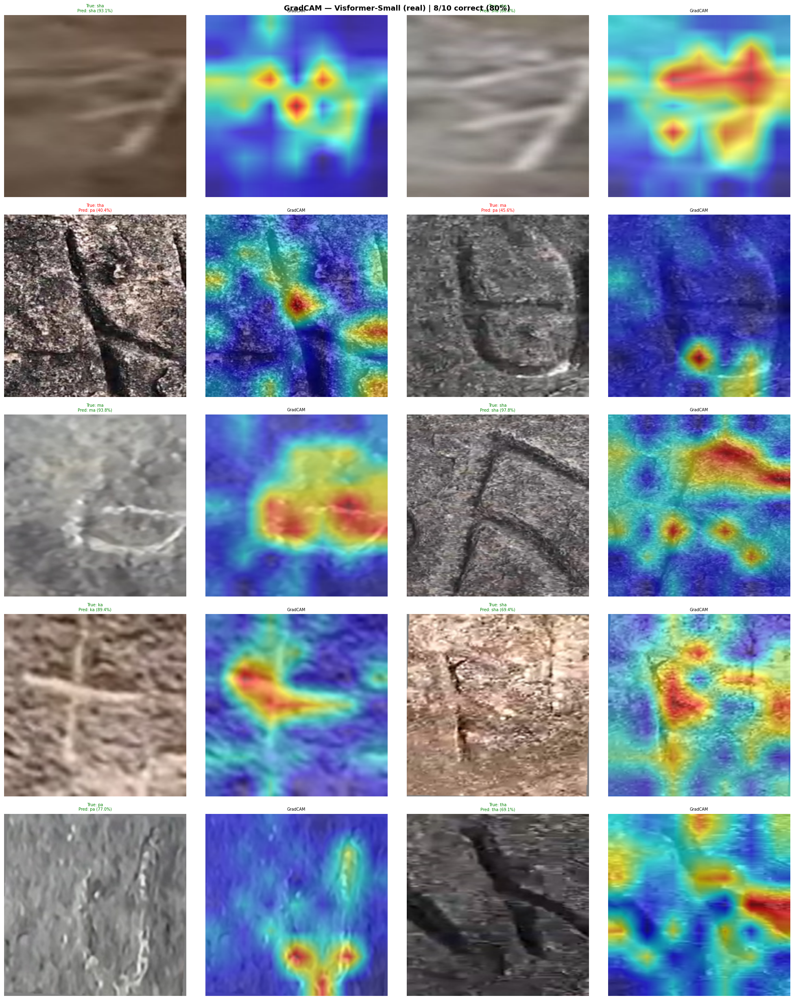

  ✅ GradCAM grid saved → /kaggle/working/brahmi_revision/gradcam_real/gradcam_grid.png
  ✅ 10 individual GradCAM images → /kaggle/working/brahmi_revision/gradcam_real/gradcam/
   train 100.00 | test 84.75 | TTA 83.05 | F1 84.18 | real photos 83.05 | 3.6 min

[2/22] synthetic/Visformer_S   (elapsed 3.6 min)


   [synthetic/Visformer_S] best val 99.56% at epoch 34 (raw weights), 60 epochs


TTA Evaluation: 100%|██████████| 4/4 [00:01<00:00,  3.35it/s, acc=35.59%]


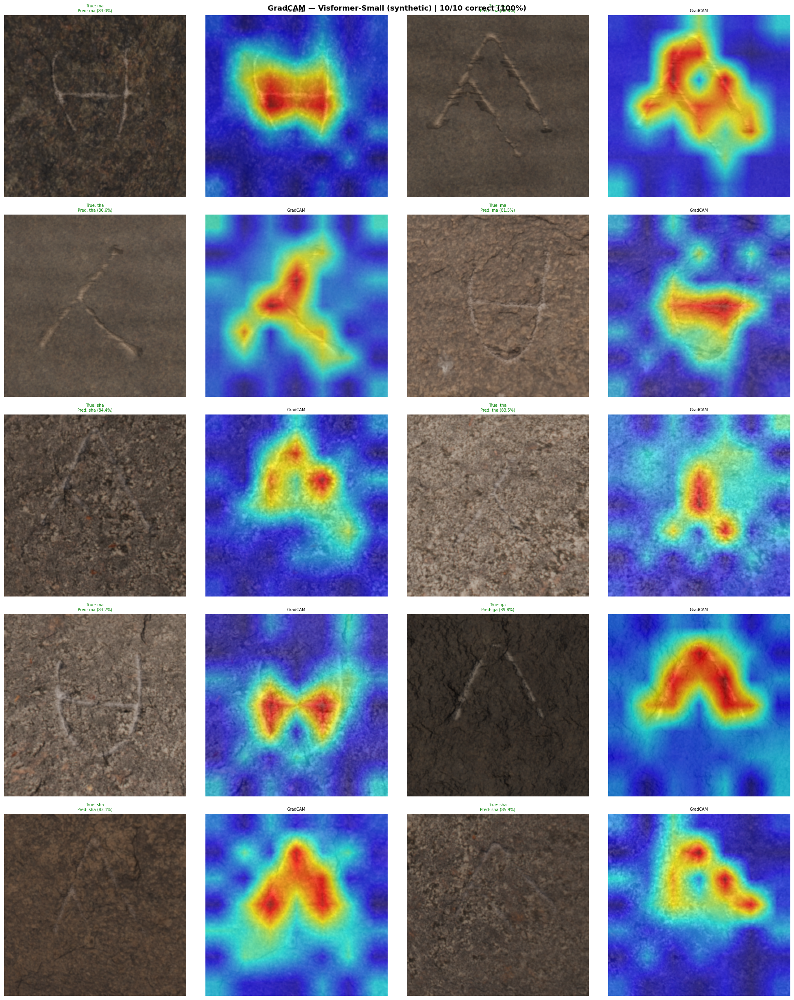

  ✅ GradCAM grid saved → /kaggle/working/brahmi_revision/gradcam_synthetic/gradcam_grid.png
  ✅ 10 individual GradCAM images → /kaggle/working/brahmi_revision/gradcam_synthetic/gradcam/
   train 100.00 | test 100.00 | TTA 100.00 | F1 100.00 | real photos 35.59 | 10.7 min

[3/22] real_synthetic/Visformer_S   (elapsed 14.3 min)


   [real_synthetic/Visformer_S] best val 98.23% at epoch 41 (raw weights), 60 epochs


TTA Evaluation: 100%|██████████| 4/4 [00:01<00:00,  3.34it/s, acc=93.22%]


   train 100.00 | test 97.89 | TTA 98.24 | F1 97.92 | real photos 93.22 | 12.8 min

[4/22] real/BasicCNN   (elapsed 27.1 min)


   [real/BasicCNN] best val 29.31% at epoch 13 (raw weights), 33 epochs


TTA Evaluation: 100%|██████████| 4/4 [00:00<00:00,  8.03it/s, acc=20.34%]


... (39 outputs left out)

   train 66.79 | test 61.02 | TTA 69.49 | F1 62.08 | real photos 69.49 | 2.7 min

[16/22] real/ViT_S16_ft   (elapsed 119.7 min)


   [real/ViT_S16_ft] best val 98.28% at epoch 34 (raw weights), 58 epochs


TTA Evaluation: 100%|██████████| 4/4 [00:00<00:00,  4.77it/s, acc=93.22%]


   train 94.46 | test 93.22 | TTA 93.22 | F1 93.57 | real photos 93.22 | 3.0 min

[17/22] real/RF   (elapsed 122.7 min)
   train 100.00 | test 32.20 | TTA - | F1 33.60 | real photos 32.20 | 0.0 min

[18/22] synthetic/RF   (elapsed 122.7 min)
   train 100.00 | test 39.56 | TTA - | F1 40.18 | real photos 16.95 | 0.2 min

[19/22] real_synthetic/RF   (elapsed 122.9 min)
   train 100.00 | test 36.27 | TTA - | F1 36.30 | real photos 30.51 | 0.1 min

[20/22] real/XGB   (elapsed 123.0 min)
   train 100.00 | test 32.20 | TTA - | F1 32.56 | real photos 32.20 | 0.9 min

[21/22] synthetic/XGB   (elapsed 123.9 min)
   train 100.00 | test 40.89 | TTA - | F1 40.48 | real photos 11.86 | 2.5 min

[22/22] real_synthetic/XGB   (elapsed 126.4 min)
   train 100.00 | test 38.03 | TTA - | F1 37.51 | real photos 32.20 | 4.1 min

Finished: 22/22 runs (130.5 min in this session)


In [11]:
# ============================================================
# R6: Run everything. Resumable: finished runs are skipped, and a run that was cut off
#     continues from its last checkpoint. Each run has its own result file, so runs done in
#     different sessions, or on different machines, can simply be put together in runs/.
# ============================================================
def _stem(rid):
    return rid.replace("/", "__")


def ckpt_file(rid):
    return f"{CKPT_DIR}/{_stem(rid)}.pt"


def write_run(rid, res):
    path = f"{RUN_DIR}/{_stem(rid)}.json"
    with open(path + ".tmp", "w") as f:
        json.dump(res, f)
    os.replace(path + ".tmp", path)


def load_results():
    out = {}
    for f in sorted(os.listdir(RUN_DIR)):
        if f.endswith(".json"):
            with open(f"{RUN_DIR}/{f}") as fh:
                out[f[:-5].replace("__", "/")] = json.load(fh)
    return out


# Results from earlier sessions: the single-file format of the previous version of this notebook and,
# on Kaggle, result files and checkpoints found in the inputs (an uploaded copy of brahmi_revision
# from Drive, or the output of an earlier version of this notebook).
old_files = [RESULTS_JSON] if os.path.exists(RESULTS_JSON) else []
run_files, ckpt_files = [], []
for base in IMPORT_DIRS:
    for root, _, files in os.walk(base):
        for f in files:
            if f in ("revision_results.json", "revision_results.json.migrated"):
                old_files.append(os.path.join(root, f))
            elif os.path.basename(root) == "runs" and f.endswith(".json") and f.split("__")[0] in CONFIGS:
                run_files.append(os.path.join(root, f))
            elif os.path.basename(root) == "checkpoints" and f.endswith(".pt"):
                ckpt_files.append(os.path.join(root, f))
for src in run_files:
    if not os.path.exists(f"{RUN_DIR}/{os.path.basename(src)}"):
        shutil.copy(src, RUN_DIR)
        print(f"Imported finished run {os.path.basename(src)[:-5].replace('__', '/')}")
for path in old_files:
    with open(path) as f:
        old = json.load(f)
    new = [rid for rid in old if not os.path.exists(f"{RUN_DIR}/{_stem(rid)}.json")]
    for rid in new:
        write_run(rid, old[rid])
    if path == RESULTS_JSON:
        os.replace(RESULTS_JSON, RESULTS_JSON + ".migrated")
    print(f"Imported {len(new)} finished runs from {path}")
for src in ckpt_files:                                 # only for runs that have not finished
    name = os.path.basename(src)
    if not os.path.exists(f"{RUN_DIR}/{name[:-3]}.json") and not os.path.exists(f"{CKPT_DIR}/{name}"):
        shutil.copy(src, CKPT_DIR)
        print(f"Imported checkpoint of unfinished run {name[:-3].replace('__', '/')}")


def run_neural(name, key):
    rid = f"{key}/{name}"
    L = LOADERS[key]
    set_seed(42)
    model, criterion, optimizer, scheduler = build_neural(name, L)
    total, trainable = count_params(model)
    model, info = train_model(model, criterion, optimizer, scheduler, L, rid, ckpt_file(rid))
    res = evaluate_neural(model, key, L)
    res.update(info, params_M=total, trainable_M=trainable,
               env={"torch": torch.__version__.split("+")[0], "cuda": str(torch.version.cuda),
                    "timm": timm.__version__, "gpu": torch.cuda.get_device_name(0)})
    if name == "Visformer_S":
        torch.save(model.state_dict(), f"{OUT_DIR}/weights/visformer_{key}.pth")
        if key in ("real", "synthetic"):               # Grad-CAM figures for the paper
            random.seed(42)
            gdir = f"{OUT_DIR}/gradcam_{key}"
            ok, tot = generate_gradcam_for_dataset(model, LE, L["X_te"], L["y_te"],
                                                   {"description": f"Visformer-Small ({key})"}, gdir, n_samples=10)
            shutil.copy(f"{gdir}/gradcam_grid.png", f"{FIG_DIR}/gradcam_{key}.png")
            res["gradcam"] = f"{ok}/{tot}"
    del model, criterion, optimizer, scheduler
    return res


t0 = time.time()
for i, (key, name) in enumerate(PLAN, 1):
    rid = f"{key}/{name}"
    results = load_results()                           # also picks up runs finished in another session
    if rid in results:
        print(f"[{i}/{len(PLAN)}] {rid}: already done, skipped")
        continue
    if rid in SKIP_RUNS:
        print(f"[{i}/{len(PLAN)}] {rid}: skipped on this machine (see R1)")
        continue
    neural = name not in CLASSICAL
    if neural and not HAS_GPU:
        print(f"[{i}/{len(PLAN)}] {rid}: needs a GPU, left for a GPU session")
        continue
    print(f"\n[{i}/{len(PLAN)}] {rid}   (elapsed {(time.time() - t0) / 60:.1f} min)")
    t1 = time.time()
    try:
        res = run_neural(name, key) if neural else run_classical(name, key)
        res["minutes"] = (time.time() - t1) / 60
        write_run(rid, res)
        if os.path.exists(ckpt_file(rid)):
            os.remove(ckpt_file(rid))                  # the run is saved; its checkpoint is no longer needed
        tta = f"{res['TTA']:.2f}" if "TTA" in res else "-"
        print(f"   train {res['Train']:.2f} | test {res['Test']:.2f} | TTA {tta} | "
              f"F1 {res['F1']:.2f} | real photos {res.get('RealTTA', res['RealAcc']):.2f} | {res['minutes']:.1f} min")
    except Exception as e:
        traceback.print_exc()
        print(f"   FAILED: {e}. Continuing; Run all again afterwards to retry it.")
    finally:
        gc.collect()
        if HAS_GPU:
            torch.cuda.empty_cache()

results = load_results()
left = [f"{k}/{m}" for k, m in PLAN if f"{k}/{m}" not in results]
print(f"\nFinished: {len(PLAN) - len(left)}/{len(PLAN)} runs "
      f"({(time.time() - t0) / 60:.1f} min in this session)")
if left:
    print("Still to do:", ", ".join(left))

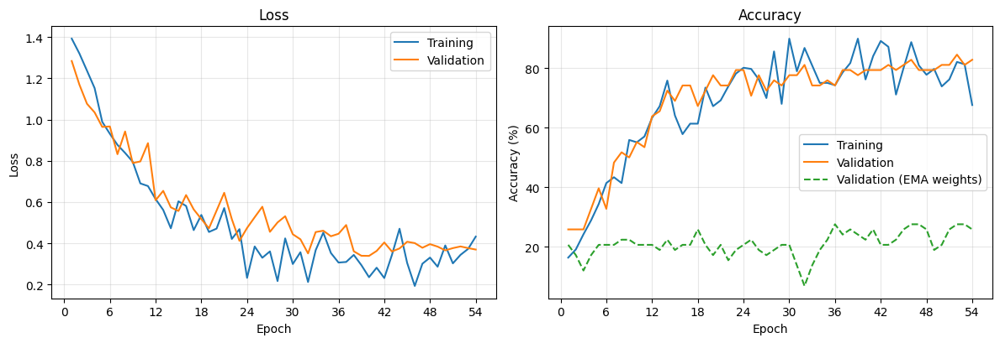

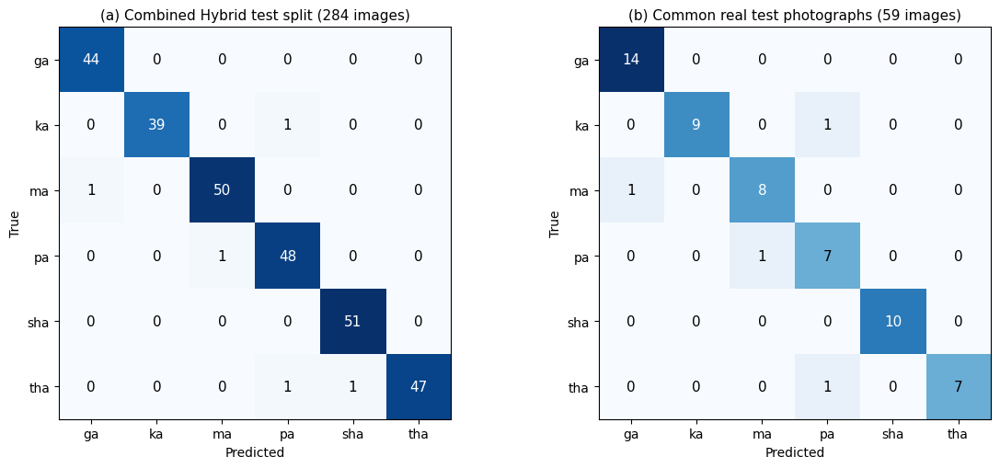

Figures saved in /kaggle/working/brahmi_revision/figures: ['confusion_matrices.png', 'gradcam_real.png', 'gradcam_synthetic.png', 'training_curves_real.png']


In [12]:
# ============================================================
# R7: Figures 6 and 7 for the paper (each is skipped until the run it needs has finished)
# ============================================================
results = load_results()

if "real/Visformer_S" in results:
    r = results["real/Visformer_S"]
    h = r["history"]
    ep = range(1, len(h["val_acc"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(ep, h["train_loss"], label="Training")
    ax[0].plot(ep, h["val_loss"], label="Validation")
    ax[0].set(xlabel="Epoch", ylabel="Loss", title="Loss")
    ax[1].plot(ep, h["train_acc"], label="Training")
    ax[1].plot(ep, h["val_acc"], label="Validation")
    ax[1].plot(ep, h["ema_val_acc"], "--", label="Validation (EMA weights)")
    ax[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend()
        a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/training_curves_real.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Training-curve figure skipped: real/Visformer_S has not finished yet")

if "real_synthetic/Visformer_S" in results:
    r = results["real_synthetic/Visformer_S"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
    panels = [(r["test_true"], r["test_pred_tta"], "(a) Combined Hybrid test split (%d images)" % len(r["test_true"])),
              (r["real_true"], r["real_pred_tta"], "(b) Common real test photographs (%d images)" % len(r["real_true"]))]
    for a, (t, p, title) in zip(axes, panels):
        cm = confusion_matrix(t, p, labels=list(range(NUM_CLASSES)))
        a.imshow(cm, cmap="Blues")
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                a.text(j, i, cm[i, j], ha="center", va="center", fontsize=11,
                       color="white" if cm[i, j] > cm.max() / 2 else "black")
        a.set_xticks(range(NUM_CLASSES))
        a.set_xticklabels(CLASSES)
        a.set_yticks(range(NUM_CLASSES))
        a.set_yticklabels(CLASSES)
        a.set(xlabel="Predicted", ylabel="True")
        a.set_title(title, fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/confusion_matrices.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Confusion-matrix figure skipped: real_synthetic/Visformer_S has not finished yet")

print(f"Figures saved in {FIG_DIR}: {sorted(os.listdir(FIG_DIR))}")

In [13]:
# ============================================================
# R8: Values for the paper -> paste the printed \setresv lines into the preamble
# ============================================================
results = load_results()

PAPER_KEYS = ["CNNCombF1", "CNNCombRealAcc", "CNNCombTest", "CNNParams", "CNNRealF1", "CNNRealRealAcc", "CNNRealTest", "CNNSynF1", "CNNSynRealAcc", "CNNSynTest", "RFCombF1", "RFCombRealAcc", "RFCombTest", "RFRealF1", "RFRealRealAcc", "RFRealTest", "RFSynF1", "RFSynRealAcc", "RFSynTest", "ResNetCombF1", "ResNetCombGap", "ResNetCombRealTTA", "ResNetCombTTA", "ResNetCombTest", "ResNetCombTrain", "ResNetParams", "ResNetRealF1", "ResNetRealGap", "ResNetRealRealTTA", "ResNetRealTTA", "ResNetRealTest", "ResNetRealTrain", "VGGCombF1", "VGGCombGap", "VGGCombRealTTA", "VGGCombTTA", "VGGCombTest", "VGGCombTrain", "VGGParams", "VGGRealF1", "VGGRealGap", "VGGRealRealTTA", "VGGRealTTA", "VGGRealTest", "VGGRealTrain", "ViTfrCombF1", "ViTfrCombGap", "ViTfrCombRealTTA", "ViTfrCombTTA", "ViTfrCombTest", "ViTfrCombTrain", "ViTfrRealF1", "ViTfrRealGap", "ViTfrRealRealTTA", "ViTfrRealTTA", "ViTfrRealTest", "ViTfrRealTrain", "ViTfrTrainable", "ViTftCombF1", "ViTftCombGap", "ViTftCombRealTTA", "ViTftCombTTA", "ViTftCombTest", "ViTftCombTrain", "ViTftParams", "ViTftRealF1", "ViTftRealGap", "ViTftRealRealTTA", "ViTftRealTTA", "ViTftRealTest", "ViTftRealTrain", "VisCombF1", "VisCombGap", "VisCombRealAcc", "VisCombRealTTA", "VisCombSynTTA", "VisCombTTA", "VisCombTest", "VisCombTrain", "VisGainReal", "VisMinusCNNComb", "VisMinusCNNReal", "VisMinusCNNSyn", "VisParams", "VisRealF1", "VisRealGap", "VisRealRealAcc", "VisRealRealTTA", "VisRealTTA", "VisRealTest", "VisRealTrain", "VisSynF1", "VisSynRealAcc", "VisSynRealTTA", "VisSynTTA", "VisSynTest", "XGBCombF1", "XGBCombRealAcc", "XGBCombTest", "XGBRealF1", "XGBRealRealAcc", "XGBRealTest", "XGBSynF1", "XGBSynRealAcc", "XGBSynTest", "XcepCombF1", "XcepCombGap", "XcepCombRealTTA", "XcepCombTTA", "XcepCombTest", "XcepCombTrain", "XcepParams", "XcepRealF1", "XcepRealGap", "XcepRealRealTTA", "XcepRealTTA", "XcepRealTest", "XcepRealTrain", "bestSotaComb", "bestSotaCombTTA", "bestSotaReal", "bestSotaRealTTA", "classicalMax", "cmCombErrors", "cmCombPairs", "cmRealErrors", "cmRealPairs", "cudaVersion", "curveBestEpoch", "curveEpochs", "curvePeakVal", "gcRealCorrect", "gcSynCorrect", "gpuName", "mcnemarB", "mcnemarC", "mcnemarP", "timmVersion", "torchVersion"]

CFG = {"real": "Real", "synthetic": "Syn", "real_synthetic": "Comb"}
MOD = {"Visformer_S": "Vis", "RF": "RF", "XGB": "XGB", "BasicCNN": "CNN", "VGG16": "VGG",
       "ResNet34": "ResNet", "Xception": "Xcep", "ViT_S16_frozen": "ViTfr", "ViT_S16_ft": "ViTft"}
f2 = lambda v: f"{v:.2f}"
signed = lambda v: ("+" if v >= 0 else "$-$") + f"{abs(v):.2f}"
gapfmt = lambda v: f"{v:.2f}" if v >= 0 else f"$-${abs(v):.2f}"

V = {}
for rid, r in results.items():
    key, name = rid.split("/")
    p = MOD[name] + CFG[key]
    for m in ("Train", "Test", "TTA", "F1", "RealAcc", "RealTTA", "SynTTA"):
        if m in r:
            V[p + m] = f2(r[m])
    V[p + "Gap"] = gapfmt(r["Gap"])
    if "params_M" in r:
        V[MOD[name] + "Params"] = f2(r["params_M"])
        V[MOD[name] + "Trainable"] = f"{r['trainable_M']:.4f}" if r["trainable_M"] < 0.01 else f2(r["trainable_M"])


def have(*rids):
    return all(x in results for x in rids)


if have("real/Visformer_S", "real_synthetic/Visformer_S"):
    a, b = results["real/Visformer_S"], results["real_synthetic/Visformer_S"]
    assert a["real_true"] == b["real_true"], "real test photographs differ between runs"
    V["VisGainReal"] = signed(b["RealTTA"] - a["RealTTA"])
    ca = np.array(a["real_pred_tta"]) == np.array(a["real_true"])
    cb = np.array(b["real_pred_tta"]) == np.array(b["real_true"])
    nb, nc = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    pval = binomtest(min(nb, nc), nb + nc, 0.5).pvalue if nb + nc > 0 else 1.0
    V["mcnemarB"], V["mcnemarC"] = str(nb), str(nc)
    V["mcnemarP"] = "$<$0.001" if pval < 0.001 else f"{pval:.3f}"

for c in CFG:
    if have(f"{c}/Visformer_S", f"{c}/BasicCNN"):
        V["VisMinusCNN" + CFG[c]] = signed(results[f"{c}/Visformer_S"]["Test"] - results[f"{c}/BasicCNN"]["Test"])

classical = [results[f"{c}/{m}"]["Test"] for c in CFG for m in ("RF", "XGB") if f"{c}/{m}" in results]
if classical:
    V["classicalMax"] = f2(max(classical))

sota = {m: results[f"real_synthetic/{m}"] for m in SOTA_MODELS if f"real_synthetic/{m}" in results}
if sota:
    m = max(sota, key=lambda k: sota[k]["TTA"])
    V["bestSotaComb"], V["bestSotaCombTTA"] = SOTA_MODELS[m]["label"], f2(sota[m]["TTA"])
    m = max(sota, key=lambda k: sota[k]["RealTTA"])
    V["bestSotaReal"], V["bestSotaRealTTA"] = SOTA_MODELS[m]["label"], f2(sota[m]["RealTTA"])

if have("real/Visformer_S"):
    r = results["real/Visformer_S"]
    V["curvePeakVal"], V["curveBestEpoch"] = f2(r["best_val"]), str(r["best_epoch"])
    V["curveEpochs"] = str(len(r["history"]["val_acc"]))
    V["gcRealCorrect"] = r.get("gradcam", "")
if have("synthetic/Visformer_S"):
    V["gcSynCorrect"] = results["synthetic/Visformer_S"].get("gradcam", "")


def confusions(true, pred):
    cm = confusion_matrix(true, pred, labels=list(range(NUM_CLASSES)))
    items = sorted(((cm[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)
                    if i != j and cm[i, j] > 0), key=lambda x: -x[0])
    text = ", ".join(f"\\textit{{{CLASSES[i]}}}$\\rightarrow$\\textit{{{CLASSES[j]}}} ({n})" for n, i, j in items)
    return str(int(sum(n for n, _, _ in items))), text or "none"


if have("real_synthetic/Visformer_S"):
    r = results["real_synthetic/Visformer_S"]
    V["cmCombErrors"], V["cmCombPairs"] = confusions(r["test_true"], r["test_pred_tta"])
    V["cmRealErrors"], V["cmRealPairs"] = confusions(r["real_true"], r["real_pred_tta"])

# Software and GPU of the training runs (each neural run records its own). If runs were done on
# different machines, every distinct value is listed, so the paper can say so.
envs = [r["env"] for r in results.values() if "env" in r]
if not envs and HAS_GPU:                               # runs from the earliest version did not record it
    envs = [{"torch": torch.__version__.split("+")[0], "cuda": str(torch.version.cuda),
             "timm": timm.__version__, "gpu": torch.cuda.get_device_name(0)}]
if envs:
    distinct = lambda k: " / ".join(sorted({e[k] for e in envs}))
    V["torchVersion"], V["cudaVersion"] = distinct("torch"), distinct("cuda")
    V["timmVersion"], V["gpuName"] = distinct("timm"), distinct("gpu")

missing = [k for k in PAPER_KEYS if k not in V]
lines = [f"\\setresv{{{k}}}{{{V[k]}}}" for k in PAPER_KEYS if k in V]
open(f"{OUT_DIR}/results_values.tex", "w").write("\n".join(lines) + "\n")
print("% ---- paste between the BEGIN/END markers in the paper preamble ----")
print("\n".join(lines))
print(f"\n{len(lines)}/{len(PAPER_KEYS)} values written to {OUT_DIR}/results_values.tex")
if missing:
    print(f"MISSING ({len(missing)}): {missing}\n-> some runs failed or have not finished; Run all again (with a GPU for the neural runs).")

% ---- paste between the BEGIN/END markers in the paper preamble ----
\setresv{CNNCombF1}{37.09}
\setresv{CNNCombRealAcc}{33.90}
\setresv{CNNCombTest}{38.03}
\setresv{CNNParams}{0.24}
\setresv{CNNRealF1}{20.59}
\setresv{CNNRealRealAcc}{20.34}
\setresv{CNNRealTest}{20.34}
\setresv{CNNSynF1}{69.97}
\setresv{CNNSynRealAcc}{10.17}
\setresv{CNNSynTest}{68.00}
\setresv{RFCombF1}{36.30}
\setresv{RFCombRealAcc}{30.51}
\setresv{RFCombTest}{36.27}
\setresv{RFRealF1}{33.60}
\setresv{RFRealRealAcc}{32.20}
\setresv{RFRealTest}{32.20}
\setresv{RFSynF1}{40.18}
\setresv{RFSynRealAcc}{16.95}
\setresv{RFSynTest}{39.56}
\setresv{ResNetCombF1}{77.72}
\setresv{ResNetCombGap}{4.67}
\setresv{ResNetCombRealTTA}{64.41}
\setresv{ResNetCombTTA}{84.86}
\setresv{ResNetCombTest}{77.46}
\setresv{ResNetCombTrain}{82.13}
\setresv{ResNetParams}{21.29}
\setresv{ResNetRealF1}{26.69}
\setresv{ResNetRealGap}{$-$6.00}
\setresv{ResNetRealRealTTA}{25.42}
\setresv{ResNetRealTTA}{25.42}
\setresv{ResNetRealTest}{32.20}
\setresv{

In [14]:
# ============================================================
# R9: Put the figures and the values file in one ZIP in the results folder
# ============================================================
zpath = f"{OUT_DIR}/revision_outputs.zip"
with zipfile.ZipFile(zpath, "w") as z:
    if os.path.exists(f"{OUT_DIR}/results_values.tex"):
        z.write(f"{OUT_DIR}/results_values.tex", "results_values.tex")
    for f in sorted(os.listdir(FIG_DIR)):
        z.write(f"{FIG_DIR}/{f}", f)
print(f"Figures and values -> {zpath}")

Figures and values -> /kaggle/working/brahmi_revision/revision_outputs.zip


In [15]:
# ============================================================
# R10: Finish. On Colab, release the runtime: a connected session keeps using your quota even
#      when nothing runs (set AUTO_RELEASE = False in R1 to keep it). On Kaggle a
#      "Save & Run All" session ends by itself.
# ============================================================
if PLATFORM == "colab" and AUTO_RELEASE:
    from google.colab import drive, runtime
    drive.flush_and_unmount()          # make sure every file has finished syncing to Drive
    print("All files synced to Drive. Disconnecting the runtime.")
    runtime.unassign()
else:
    where = "the notebook's Output, folder brahmi_revision/" if PLATFORM == "kaggle" else OUT_DIR
    print(f"Done. Values, figures and revision_outputs.zip are in {where}")

Done. Values, figures and revision_outputs.zip are in the notebook's Output, folder brahmi_revision/
